In [5]:
!pip -q install tensorflow-datasets scikit-learn matplotlib pillow importlib_resources

In [6]:
import os, json, random, shutil, pathlib, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.model_selection import train_test_split
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
CLASS_NAMES = ["dog", "cat", "neither"] # fixed output order throughout the project
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [7]:
pet_train, pet_info = tfds.load(
"oxford_iiit_pet", split="train", with_info=True, as_supervised=False
)
pet_test = tfds.load("oxford_iiit_pet", split="test", as_supervised=False)
print("Oxford features:", pet_info.features)
print("Oxford species names:", pet_info.features["species"].names)
print("Oxford breed names:", pet_info.features["label"].names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Oxford features: FeaturesDict({
    'file_name': Text(shape=(), dtype=string),
    'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=37),
    'segmentation_mask': Image(shape=(None, None, 1), dtype=uint8),
    'species': ClassLabel(shape=(), dtype=int64, num_classes=2),
})
Oxford species names: ['Cat', 'Dog']
Oxford breed names: ['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'Bengal', 'Birman', 'Bombay', 'boxer', 'British_Shorthair', 'chihuahua', 'Egyptian_Mau', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'Maine_Coon', 'miniature_pinscher', 'newfoundland', 'Persian', 'pomeranian', 'pug', 'Ragdoll',

In [8]:
import importlib
importlib.invalidate_caches()
import importlib_resources

# Retry loading the dataset
pet_train, pet_info = tfds.load(
    "oxford_iiit_pet", split="train", with_info=True, as_supervised=False
)
pet_test = tfds.load("oxford_iiit_pet", split="test", as_supervised=False)
print("Oxford features:", pet_info.features)
print("Oxford species names:", pet_info.features["species"].names)
print("Oxford breed names:", pet_info.features["label"].names)

Oxford features: FeaturesDict({
    'file_name': Text(shape=(), dtype=string),
    'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=37),
    'segmentation_mask': Image(shape=(None, None, 1), dtype=uint8),
    'species': ClassLabel(shape=(), dtype=int64, num_classes=2),
})
Oxford species names: ['Cat', 'Dog']
Oxford breed names: ['Abyssinian', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'Bengal', 'Birman', 'Bombay', 'boxer', 'British_Shorthair', 'chihuahua', 'Egyptian_Mau', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'Maine_Coon', 'miniature_pinscher', 'newfoundland', 'Persian', 'pomeranian', 'pug', 'Ragdoll', 'Russian_Blue', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'Siamese', 'Sphynx', 'staffordshire_bull_terrier', 'wheaten_t

In [9]:
cal_ds, cal_info = tfds.load("caltech101", split="train", with_info=True, as_supervised=False)
cal_label_names = cal_info.features["label"].names
print("Caltech-101 categories:")
print(cal_label_names)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.G8F1CB_3.0.2/caltech101-train.tfrecord-[0-9][0-9][0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/caltech101/incomplete.G8F1CB_3.0.2/caltech101-test.tfrecord-[0-9][0-9][0-9…

Dataset caltech101 downloaded and prepared to /root/tensorflow_datasets/caltech101/3.0.2. Subsequent calls will reuse this data.
Caltech-101 categories:
['accordion', 'airplanes', 'anchor', 'ant', 'background_google', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill', 'dolphin', 'dragonfly', 'electric_guitar', 'elephant', 'emu', 'euphonium', 'ewer', 'faces', 'faces_easy', 'ferry', 'flamingo', 'flamingo_head', 'garfield', 'gerenuk', 'gramophone', 'grand_piano', 'hawksbill', 'headphone', 'hedgehog', 'helicopter', 'ibis', 'inline_skate', 'joshua_tree', 'kangaroo', 'ketch', 'lamp', 'laptop', 'leopards', 'llama', 'lobster', 'lotus', 'mandolin', 'mayfly', 'menorah', 'metronome', 'minaret', 'motorbikes', 'nautilus', 'octopus', 'okapi', 'pagoda', 'pan

In [10]:
EXTRA_EXCLUDE_TERMS = [] # add any extra category names that should not be considered "neither"
EXCLUDE_TERMS = ["dog", "cat", "canine", "feline"] + [x.lower() for x in EXTRA_EXCLUDE_TERMS]
negative_labels = [
i for i, name in enumerate(cal_label_names)
if not any(term in name.lower() for term in EXCLUDE_TERMS)
]
excluded_labels = [name for i, name in enumerate(cal_label_names) if i not in negative_labels]
print("Excluded Caltech categories:", excluded_labels)
print("Categories available for neither:", len(negative_labels))
assert len(negative_labels) > 0, "No Caltech categories left after filtering."

Excluded Caltech categories: ['wild_cat']
Categories available for neither: 101


In [11]:
print("Species label names:", pet_info.features["species"].names)

Species label names: ['Cat', 'Dog']


In [12]:
# Map species IDs by the dataset's actual label names.
species_names = [str(x).lower() for x in pet_info.features["species"].names]
cat_id = next(i for i, name in enumerate(species_names) if "cat" in name)
dog_id = next(i for i, name in enumerate(species_names) if "dog" in name)
print("cat_id =", cat_id, "| dog_id =", dog_id)

MAX_PET_TRAIN_PER_CLASS = 1800
MAX_PET_TEST_PER_CLASS = 700
MAX_NEGATIVE_IMAGES = 2500

def image_to_array(image, size=IMG_SIZE):
    image = tf.image.resize(image, size, antialias=True)
    image = tf.cast(image, tf.uint8)
    return image.numpy()

def collect_pet(ds, per_class_limit=None):
    xs, ys, counts = [], [], {"cat": 0, "dog": 0}
    for item in tfds.as_numpy(ds):
        species = int(item["species"])
        if species == cat_id:
            cls = "cat"
        elif species == dog_id:
            cls = "dog"
        else:
            continue
        if per_class_limit is not None and counts[cls] >= per_class_limit:
            continue
        xs.append(image_to_array(item["image"]))
        ys.append(1 if cls == "cat" else 0) # dog=0, cat=1, neither=2
        counts[cls] += 1
    return np.asarray(xs, dtype=np.uint8), np.asarray(ys, dtype=np.int32), counts

X_pet_train, y_pet_train, pet_train_counts = collect_pet(pet_train, MAX_PET_TRAIN_PER_CLASS)
X_pet_test, y_pet_test, pet_test_counts = collect_pet(pet_test, MAX_PET_TEST_PER_CLASS)
print("Oxford train:", X_pet_train.shape, pet_train_counts)
print("Oxford test:", X_pet_test.shape, pet_test_counts)

cat_id = 0 | dog_id = 1
Oxford train: (2988, 160, 160, 3) {'cat': 1188, 'dog': 1800}
Oxford test: (1400, 160, 160, 3) {'cat': 700, 'dog': 700}


In [13]:
X_neg, y_neg, neg_names = [], [], []
for item in tfds.as_numpy(cal_ds):
    label = int(item["label"])
    if label not in negative_labels:
        continue
    if len(X_neg) >= MAX_NEGATIVE_IMAGES:
        break
    X_neg.append(image_to_array(item["image"]))
    y_neg.append(2)
    neg_names.append(cal_label_names[label])

X_neg = np.asarray(X_neg, dtype=np.uint8)
y_neg = np.asarray(y_neg, dtype=np.int32)
print("Neither examples:", X_neg.shape)
print("Example negative categories:", sorted(set(neg_names))[:30])
assert len(X_neg) >= 100, "Too few negative images collected; inspect the dataset loading and category filter."

Neither examples: (2500, 160, 160, 3)
Example negative categories: ['accordion', 'airplanes', 'anchor', 'ant', 'background_google', 'barrel', 'bass', 'beaver', 'binocular', 'bonsai', 'brain', 'brontosaurus', 'buddha', 'butterfly', 'camera', 'cannon', 'car_side', 'ceiling_fan', 'cellphone', 'chair', 'chandelier', 'cougar_body', 'cougar_face', 'crab', 'crayfish', 'crocodile', 'crocodile_head', 'cup', 'dalmatian', 'dollar_bill']


In [14]:
# Split positive pet training images into training and validation.
X_pos_train, X_pos_val, y_pos_train, y_pos_val = train_test_split(
    X_pet_train, y_pet_train, test_size=0.15, random_state=SEED, stratify=y_pet_train
)
X_neg_train, X_neg_val, y_neg_train, y_neg_val = train_test_split(
    X_neg, y_neg, test_size=0.20, random_state=SEED, stratify=y_neg
)
X_train = np.concatenate([X_pos_train, X_neg_train])
y_train = np.concatenate([y_pos_train, y_neg_train])
X_val = np.concatenate([X_pos_val, X_neg_val])
y_val = np.concatenate([y_pos_val, y_neg_val])
# Shuffle combined data.
train_order = np.random.permutation(len(X_train))
val_order = np.random.permutation(len(X_val))
X_train, y_train = X_train[train_order], y_train[train_order]
X_val, y_val = X_val[val_order], y_val[val_order]
# Official Oxford test images are included as cat/dog test cases.
X_test = X_pet_test
y_test = y_pet_test
def show_class_counts(y, title):
    counts = {name: int(np.sum(y == i)) for i, name in enumerate(CLASS_NAMES)}
    print(title, counts)
show_class_counts(y_train, "Train")
show_class_counts(y_val, "Validation")
show_class_counts(y_test, "Official Oxford test (cat/dog only)")

Train {'dog': 1530, 'cat': 1009, 'neither': 2000}
Validation {'dog': 270, 'cat': 179, 'neither': 500}
Official Oxford test (cat/dog only) {'dog': 700, 'cat': 700, 'neither': 0}


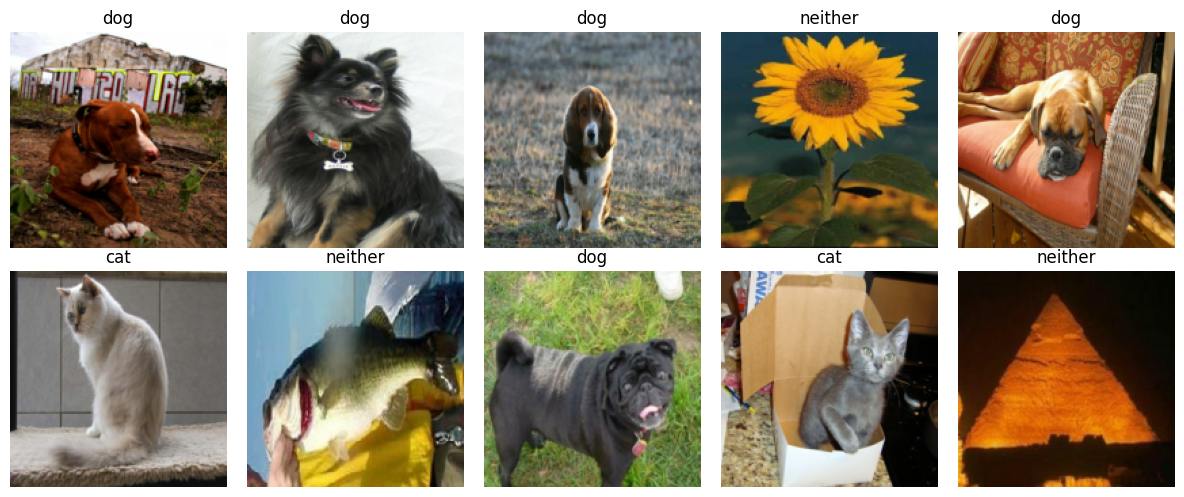

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, np.random.choice(len(X_train), min(10, len(X_train)), replace=False)):
    ax.imshow(X_train[idx])
    ax.set_title(CLASS_NAMES[int(y_train[idx])])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [16]:
from sklearn.utils.class_weight import compute_class_weight
# MobileNetV2 preprocessing expects pixels in [-1, 1].
def preprocess_batch(x):
   return tf.keras.applications.mobilenet_v2.preprocess_input(tf.cast(x, tf.float32))
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(min(len(X_train), 5000), seed=SEED).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
class_weights_values = compute_class_weight(class_weight="balanced", classes=np.unique(y_train), y=y_train)
class_weights = {int(k): float(v) for k, v in zip(np.unique(y_train), class_weights_values)}
print("Class weights:", class_weights)
base_model = tf.keras.applications.MobileNetV2(
     input_shape=(*IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name="image")
x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1, name="mobilenet_preprocess")(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(3, activation="softmax", name="class_probabilities")(x)
model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Class weights: {0: 0.9888888888888889, 1: 1.4995044598612488, 2: 0.7565}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 160, 160, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,827 (8.63 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [17]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_model.keras", monitor="val_loss", save_best_only=True)
]
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/8
142/142 ━━━━━━━━━━━━━━━━━━━━ 28s 111ms/step - accuracy: 0.8830 - loss: 0.3089 - val_accuracy: 0.9747 - val_loss: 0.1040
Epoch 2/8
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9782 - loss: 0.0885 - val_accuracy: 0.9842 - val_loss: 0.0754
Epoch 3/8
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9835 - loss: 0.0598 - val_accuracy: 0.9821 - val_loss: 0.0651
Epoch 4/8
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9894 - loss: 0.0454 - val_accuracy: 0.9810 - val_loss: 0.0654
Epoch 5/8
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9905 - loss: 0.0362 - val_accuracy: 0.9852 - val_loss: 0.0543
Epoch 6/8
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9916 - loss: 0.0324 - val_accuracy: 0.9831 - val_loss: 0.0661
Epoch 7/8
142/142 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.9918 - loss: 0.0285 - val_accuracy: 0.9831 - val_loss: 0.0563


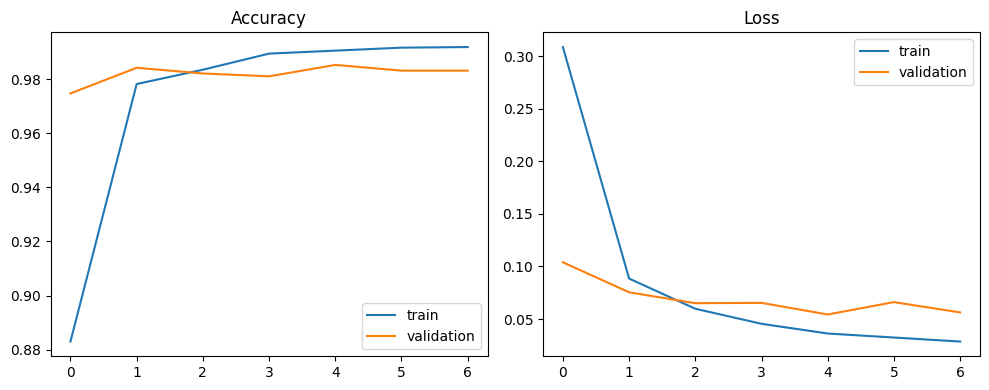

In [18]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss")
plt.legend()
plt.tight_layout()
plt.show()

Three-class validation accuracy: 0.9852
              precision    recall  f1-score   support

         dog       0.97      0.99      0.98       270
         cat       0.97      0.97      0.97       179
     neither       1.00      0.99      0.99       500

    accuracy                           0.99       949
   macro avg       0.98      0.98      0.98       949
weighted avg       0.99      0.99      0.99       949

Validation confusion matrix (rows=true, columns=predicted):
[[267   3   0]
 [  4 173   2]
 [  3   2 495]]


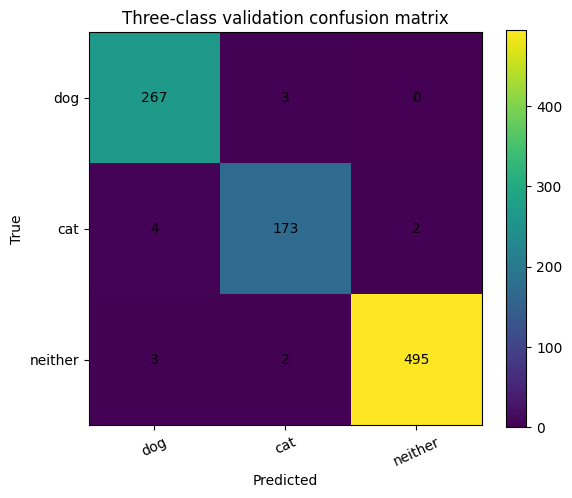

In [19]:
val_probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
val_pred = np.argmax(val_probs, axis=1)
print("Three-class validation accuracy:", round(accuracy_score(y_val, val_pred), 4))
print(classification_report(y_val, val_pred, labels=[0,1,2], target_names=CLASS_NAMES, zero_division=0))
cm = confusion_matrix(y_val, val_pred, labels=[0,1,2])
print("Validation confusion matrix (rows=true, columns=predicted):")
print(cm)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm)
ax.set_xticks(range(3), CLASS_NAMES, rotation=25)
ax.set_yticks(range(3), CLASS_NAMES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Three-class validation confusion matrix")
for i in range(3):
    for j in range(3):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [20]:
pet_probs = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
pet_pred = np.argmax(pet_probs, axis=1)
print("Oxford official test (cats/dogs only) accuracy:", round(accuracy_score(y_test, pet_pred), 4))
print(classification_report(y_test, pet_pred, labels=[0,1], target_names=["dog","cat"], zero_division=0))
print("Note: this test does not measure the model's ability to reject neither images.")

Oxford official test (cats/dogs only) accuracy: 0.9764
              precision    recall  f1-score   support

         dog       0.98      0.98      0.98       700
         cat       0.99      0.97      0.98       700

   micro avg       0.98      0.98      0.98      1400
   macro avg       0.98      0.98      0.98      1400
weighted avg       0.98      0.98      0.98      1400

Note: this test does not measure the model's ability to reject neither images.


In [21]:
from PIL import Image, UnidentifiedImageError
def predict_pil_image(pil_image):
    pil_image = pil_image.convert("RGB")
    resized = pil_image.resize((IMG_SIZE[1], IMG_SIZE[0]))
    arr = np.asarray(resized, dtype=np.uint8)[None, ...]
    probs = model.predict(arr, verbose=0)[0]
    idx = int(np.argmax(probs))
    return CLASS_NAMES[idx], float(probs[idx]), {CLASS_NAMES[i]: float(probs[i]) for i in range(3)}
# Example: replace this path with a real image file you have uploaded to Colab.
EXAMPLE_IMAGE_PATH = ""
if EXAMPLE_IMAGE_PATH and os.path.exists(EXAMPLE_IMAGE_PATH):
    with Image.open(EXAMPLE_IMAGE_PATH) as im:
         print(predict_pil_image(im))
else:
    print("Upload a test image to Colab and set EXAMPLE_IMAGE_PATH to its path.")

Upload a test image to Colab and set EXAMPLE_IMAGE_PATH to its path.


In [22]:
import pandas as pd
from PIL import Image

def predict_folder(folder_path):
    folder = pathlib.Path(folder_path)
    if not folder.exists() or not folder.is_dir():
        raise ValueError(f"Folder does not exist or is not a directory: {folder_path}")
    rows = []
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    for path in sorted(folder.iterdir()):
        if path.suffix.lower() not in valid_extensions:
            continue
        try:
            with Image.open(path) as im:
                label, confidence, all_scores = predict_pil_image(im)
            rows.append({
                "filename": path.name,
                "prediction": label,
                "confidence": round(confidence * 100, 2),
                "status": "ok"
            })
        except Exception as exc:
            rows.append({
                "filename": path.name,
                "prediction": "error",
                "confidence": None,
                "status": f"Could not read image: {type(exc).__name__}"
            })
    return pd.DataFrame(rows, columns=["filename", "prediction", "confidence", "status"])

IMAGE_FOLDER = "/content/assessment_images" # CHANGE THIS ONE PATH on assessment day
if os.path.isdir(IMAGE_FOLDER):
    results_df = predict_folder(IMAGE_FOLDER)
    display(results_df)
    results_df.to_csv("/content/predictions.csv", index=False)
    print("Saved: /content/predictions.csv")
else:
    print(f"Create/upload the folder first: {IMAGE_FOLDER}")

Create/upload the folder first: /content/assessment_images


In [23]:
MODEL_PATH = "/content/model.keras"
model.save(MODEL_PATH)
print("Saved model:", MODEL_PATH, "| bytes:", os.path.getsize(MODEL_PATH))
reloaded_model = tf.keras.models.load_model(MODEL_PATH)
sample = X_val[:3]
before = model.predict(sample, verbose=0)
after = reloaded_model.predict(sample, verbose=0)
print("Maximum difference after reload:", float(np.max(np.abs(before - after))))
assert np.allclose(before, after, atol=1e-5), "Reloaded model predictions differ unexpectedly."
print("Model reload test passed.")

Saved model: /content/model.keras | bytes: 9669149
Maximum difference after reload: 0.0
Model reload test passed.


In [24]:
# Download the saved model to your laptop.
from google.colab import files
files.download(MODEL_PATH)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
# Check model output shape, probability range, and sum.
sample_probs = model.predict(X_val[:8], verbose=0)
assert sample_probs.shape == (min(8, len(X_val)), 3)
assert np.all(sample_probs >= 0) and np.all(sample_probs <= 1)
assert np.allclose(sample_probs.sum(axis=1), 1.0, atol=1e-4)
assert set(CLASS_NAMES) == {"dog", "cat", "neither"}
print("Basic model sanity checks passed.")

Basic model sanity checks passed.


In [30]:
# PETVISION AI — TEST 15 PICTURES

from google.colab import files
from PIL import Image
from io import BytesIO
import pandas as pd

# Check that your trained model and prediction function exist
if "model" not in globals():
    raise RuntimeError("Run your model-training cells first.")

if "predict_pil_image" not in globals():
    raise RuntimeError("Run the cell containing predict_pil_image first.")

print("Select your 15 cat, dog, and neither pictures.")

# Upload pictures from your phone
uploaded = files.upload()

results = []

for filename, file_bytes in uploaded.items():
    try:
        # Open each uploaded picture
        with Image.open(BytesIO(file_bytes)) as img:
            prediction, confidence, all_scores = predict_pil_image(img)

        results.append({
            "filename": filename,
            "prediction": prediction,
            "confidence_percent": round(confidence * 100, 2),
            "status": "Success"
        })

    except Exception as error:
        results.append({
            "filename": filename,
            "prediction": "ERROR",
            "confidence_percent": None,
            "status": str(error)
        })

# Show the prediction results
results_df = pd.DataFrame(results)
print("\nPICTURE TEST RESULTS")
display(results_df)

# Save results to a CSV file
csv_path = "/content/PetVision_AI_15_Test_Results.csv"
results_df.to_csv(csv_path, index=False)

print("\nPictures uploaded:", len(uploaded))
print(
    "Pictures successfully tested:",
    sum(results_df["status"] == "Success")
)
print("Results saved successfully.")

# Download the results to your phone
files.download(csv_path)

Select your 15 cat, dog, and neither pictures.


Saving OIP (1).webp to OIP (1) (1).webp
Saving OIP.webp to OIP (2).webp
Saving OIF.webp to OIF (1).webp
Saving OIP (2).jpg to OIP (2) (1).jpg
Saving OIP (1).jpg to OIP (1) (1).jpg
Saving OIP.jpg to OIP (3).jpg

PICTURE TEST RESULTS


,filename,prediction,confidence_percent,status
0,OIP (1) (1).webp,neither,99.15,Success
1,OIP (2).webp,dog,99.96,Success
2,OIF (1).webp,cat,100.00,Success
3,OIP (2) (1).jpg,cat,99.99,Success
4,OIP (1) (1).jpg,cat,100.00,Success
5,OIP (3).jpg,cat,99.99,Success



Pictures uploaded: 6
Pictures successfully tested: 6
Results saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import os

print("Checking for your saved model...")

for folder in ["/content", "/content/drive/MyDrive"]:
    if os.path.exists(folder):
        for root, dirs, files_found in os.walk(folder):
            if "model.keras" in files_found:
                print("FOUND:", os.path.join(root, "model.keras"))
            dirs[:] = [d for d in dirs if d not in [".cache", "node_modules"]]

Checking for your saved model...
FOUND: /content/model.keras


Upload your test pictures: Cat, Dog, or Neither


Saving OIP (1).webp to OIP (1) (2).webp
Saving OIP.webp to OIP (3).webp
Saving OIF.webp to OIF (2).webp
Saving OIP (2).jpg to OIP (2) (2).jpg
Saving OIP (1).jpg to OIP (1) (2).jpg
Saving OIP.jpg to OIP (4).jpg

Picture: OIP (1) (2).webp


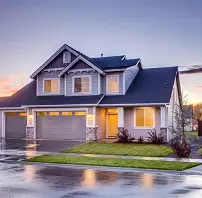

Predicted class: neither
Confidence: 99.15%
----------------------------------------

Picture: OIP (3).webp


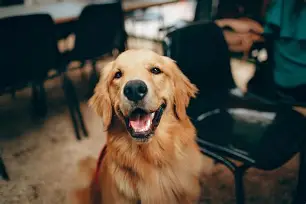

Predicted class: dog
Confidence: 99.96%
----------------------------------------

Picture: OIF (2).webp


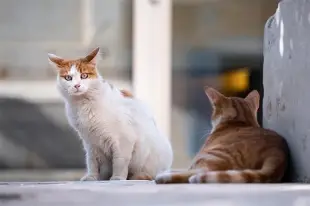

Predicted class: cat
Confidence: 100.00%
----------------------------------------

Picture: OIP (2) (2).jpg


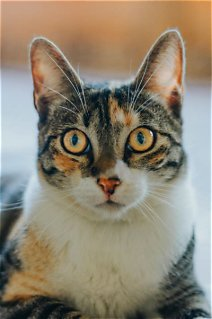

Predicted class: cat
Confidence: 99.99%
----------------------------------------

Picture: OIP (1) (2).jpg


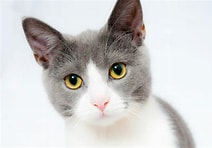

Predicted class: cat
Confidence: 100.00%
----------------------------------------

Picture: OIP (4).jpg


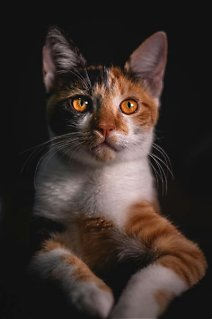

Predicted class: cat
Confidence: 99.99%
----------------------------------------

SUMMARY OF TEST RESULTS


,Picture,Prediction,Confidence (%)
0,OIP (1) (2).webp,neither,99.15
1,OIP (3).webp,dog,99.96
2,OIF (2).webp,cat,100.00
3,OIP (2) (2).jpg,cat,99.99
4,OIP (1) (2).jpg,cat,100.00
5,OIP (4).jpg,cat,99.99


Results table saved.


In [31]:
from google.colab import files
from PIL import Image
from IPython.display import display
from io import BytesIO
import pandas as pd

print("Upload your test pictures: Cat, Dog, or Neither")
uploaded = files.upload()

results = []

for filename, file_bytes in uploaded.items():
    try:
        with Image.open(BytesIO(file_bytes)) as img:
            img = img.convert("RGB")

            # Display the actual picture
            print(f"\nPicture: {filename}")
            preview = img.copy()
            preview.thumbnail((400, 400))
            display(preview)

            # Get the model's prediction
            prediction, confidence, all_scores = predict_pil_image(img)

            print(f"Predicted class: {prediction}")
            print(f"Confidence: {confidence * 100:.2f}%")
            print("-" * 40)

            results.append({
                "Picture": filename,
                "Prediction": prediction,
                "Confidence (%)": round(confidence * 100, 2)
            })

    except Exception as e:
        print(f"Could not test {filename}: {e}")

# Display a summary of the results
results_df = pd.DataFrame(results)
print("\nSUMMARY OF TEST RESULTS")
display(results_df)

# Save results for your presentation
results_df.to_csv(
    "/content/PetVision_AI_Presentation_Results.csv",
    index=False
)
print("Results table saved.")